In [1]:
import math
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

# Having a conversation with our data
### When should a BI tool or assistant ask a clarifying question? A Bayes-Shannon model tested on AdventureWorks

**Author:** baxendy (AG)

**Abstract.** *Business-intelligence (BI) tools now let people ask questions about their data in plain language. These questions are often ambiguous: 'show sales by region' does not say whether 'sales' means money or units, what level of geography is needed, or which period. Most assistants still answer with full confidence, so a wrong number looks as believable as a correct one. This notebook builds a small mathematical model of the conversation between a user and a BI assistant. The assistant counts the possible interpretations of a request (combinatorics), estimates their probabilities with Bayes' theorem (a Naive Bayes classifier), measures its uncertainty with Shannon entropy and asks a clarifying question while the entropy is above a threshold. The model is tested with 480 simulated requests to Microsoft's AdventureWorks sample data warehouse (another 120 requests serve as examples for the semantic layer), with and without a semantic layer, with and without clarifying questions.*

**Contents**
1. The problem and the hypotheses
2. Mathematical toolbox
3. The data: AdventureWorksDW
4. The simulation: semantic model and simulated users
5. The assistant with and without a semantic layer
6. The dialogue: when to ask and what to ask
7. Results
8. Conclusion
9. References

## 1. The problem and the hypotheses

BI platforms let users ask questions in natural language. A request like *show sales by region* leaves three things open on a typical sales model:

* the **measure**: sales amount (money) or order quantity (units);
* the **grouping**: sales-territory region, country or territory group;
* the **period**: last year, the year before, or all years.

A human analyst would ask back, but an assistant usually picks one interpretation and answers confidently.

The semantic layer (measures, synonyms, descriptions, default rules) helps the assistant to understand requests (Sequeda et al., 2023), and clarifying questions help to fix what is still unclear (Zhao et al., 2024). The idea that a system should decide between acting and asking is called *mixed initiative* (Horvitz, 1999). This project tests one simple, measurable rule for that decision:

> **Ask while the uncertainty of the assistant (Shannon entropy) is above a threshold τ; otherwise answer.**

| | Hypothesis |
|---|---|
| **H1** | A semantic layer lowers the initial uncertainty of the assistant. |
| **H2** | Higher uncertainty goes together with wrong answers. |
| **H3** | Clarifying questions increase the accuracy of the answers. |
| **H4** | With a semantic layer fewer clarifying questions are needed. |

**Assumptions.** The users are simulated. A request has three or four independent parts. The simulated user always answers questions correctly.



## 2. Mathematical toolbox

### 2.1 Counting interpretations: the rule of product

An interpretation chooses one value for every part of a request. If part $i$ has $n_i$ possible values, the rule of product gives the number of interpretations

$$N = n_1 \cdot n_2 \cdots n_k = \prod_{i=1}^{k} n_i .$$

For *show sales by region* with 2 measures, 3 groupings and 3 periods this is already $2 \cdot 3 \cdot 3 = 18$. A grouping is a dimension attribute that the data can be grouped by: here region, country and territory group, three levels of the same sales-territory dimension. Our semantic model has 6 measures, 6 groupings (from the territory, product and date dimensions) and 4 periods. Without a semantic layer the assistant only sees raw database columns, so it must also guess the aggregation (SUM, AVERAGE or COUNT): the measure splits into a column and an aggregation.


In [2]:
n_small_example = 2 * 3 * 3
n_with_layer = 6 * 6 * 4
n_without_layer = 6 * 3 * 6 * 4

print("Interpretations of 'show sales by region' :", n_small_example)
print("Interpretations with a semantic layer:" , n_with_layer)
print("Interpretations without a semantic layer:" , n_without_layer)

Interpretations of 'show sales by region' : 18
Interpretations with a semantic layer: 144
Interpretations without a semantic layer: 432


### 2.2 Bayes' theorem

Before reading a request $q$ the assistant has a prior probability $P(t)$ for every interpretation $t$. After reading it, Bayes' theorem gives the posterior probability

$$P(t \mid q) = \frac{P(q \mid t)\,P(t)}{P(q)}, \qquad P(q) = \sum_{t'} P(q \mid t')\,P(t').$$

$P(q \mid t)$, the likelihood, is how probable it is that a user who wants $t$ writes $q$. The denominator $P(q)$ comes from the law of total probability; it makes the posteriors sum to 1.

*Example.* The word 'sales' is used for the sales amount with probability 0.30 and for the order quantity with probability 0.20, and both measures are equally likely beforehand. A semantic layer that defines 'sales' as a synonym of Sales Amount changes the likelihoods to 0.38 and 0.02.


In [3]:
def bayes(likelihoods, priors):

    prob = [likelihood * prior for likelihood, prior in zip(likelihoods, priors)]
    total = sum(prob)
    
    return [round(value / total, 3) for value in prob]


print("'sales' without a semantic layer:", bayes([0.30, 0.20], [0.5, 0.5]))
print("'sales' with a semantic layer:", bayes([0.38, 0.02], [0.5, 0.5]))

'sales' without a semantic layer: [0.6, 0.4]
'sales' with a semantic layer: [0.95, 0.05]


### 2.3 Naive Bayes

A request has several words $w_1, w_2, \dots$ Naive Bayes assumes that the words are independent when the meaning is known, so

$$P(q \mid t) = \prod_{j} P(w_j \mid t).$$

The word probabilities are learned by counting: how often does the word $w$ appear in the examples of class $c$? With Laplace smoothing ($\alpha = 1$ is added to every count) a word that was never seen with a class does not get probability 0:

$$P(w \mid c) = \frac{\text{count}(w, c) + \alpha}{\text{count}(c) + \alpha V},$$

where $\text{count}(c)$ is the number of words seen with class $c$ and $V$ is the number of different words. Words that never appeared in the training examples are skipped. At the end every product is divided by the sum over all classes, exactly as in Bayes' theorem above, so the probabilities sum to 1.


In [4]:
STOP_WORDS = ['a', 'an', 'and', 'are', 'break', 'by', 'can', 'did', 'do', 'down',
              'each', 'for', 'give', 'have', 'how', 'in', 'is', 'list', 'me', 'much',
              'of', 'on', 'per', 'please', 'show', 'since', 'the', 'this', 'to',
              'was', 'we', 'what', 'you']


def tokenize(text):

    clean = ''

    for character in text.lower():
        if 'a' <= character <= 'z':
            clean = clean + character
        else:
            clean = clean + ' '
            
    return [word for word in clean.split() if word not in STOP_WORDS]


print(tokenize('Show total revenue by Country, last year!'))

['total', 'revenue', 'country', 'last', 'year']


In [5]:
def train_naive_bayes(examples, classes, prior=None):

    counts = {}
    totals = {}
    vocabulary = set()

    for c in classes:
        counts[c] = {}
        totals[c] = 0

    for text, label in examples:
        for word in tokenize(text):
            counts[label][word] = counts[label].get(word, 0) + 1
            totals[label] = totals[label] + 1
            vocabulary.add(word)

    if prior is None:
        prior = [1 / len(classes)] * len(classes)

    return {"classes": classes, "counts": counts, "totals": totals, "vocabulary": vocabulary, "prior": prior}


def word_probability(model, word, c):

    V = len(model["vocabulary"])
    return (model["counts"][c].get(word, 0) + 1) / (model["totals"][c] + V)


def predict(model, text):

    prob = []

    for c, prior in zip(model["classes"], model["prior"]):
        p = prior
        for word in tokenize(text):
            if word in model["vocabulary"]:
                p = p * word_probability(model, word, c)
        prob.append(p)

    total = sum(prob)

    return np.array([value / total for value in prob])


toy_model = train_naive_bayes(
    [("sales amount", "Sales Amount"), ("revenue", "Sales Amount"), ("sales", "Sales Amount"),
     ("order quantity", "Order Quantity"), ("units sold", "Order Quantity"), ("sales units", "Order Quantity")],
    ["Sales Amount", "Order Quantity"])

print("P(class | 'total sales by region') =", predict(toy_model, "total sales by region").round(3))

P(class | 'total sales by region') = [0.639 0.361]


### 2.4 Shannon entropy

The uncertainty about one part with probabilities $p_1, \dots, p_n$ is its Shannon entropy (Shannon, 1948):

$$H = -\sum_{i=1}^{n} p_i \log_2 p_i \quad \text{(in bits)}.$$

Here $\log_2 x$ is the power of 2 that gives $x$.

* $H = 0$ when one value has probability 1: there is no doubt.
* $H = \log_2 n$, the largest possible value, when all $n$ values are equally likely. One bit is the doubt of a fair coin.
* Values with probability 0 add nothing, so they are skipped.
* If the parts of a request are independent, their entropies add up: $H(T) = \sum_i H(C_i)$. So we can also see which part is the most unclear.

The code also checks the example show 'sales by region' from Section 1, with made-up probabilities. If the assistant answers with the most probable value of every part, the chance that the whole answer is right is the product of these best probabilities, because the parts are independent.

For two outcomes with probabilities $p$ and $1-p$ the entropy is $H(p) = -p\log_2 p - (1-p)\log_2(1-p)$. Its derivative is $H'(p) = \log_2\frac{1-p}{p}$, which is zero only at $p = 0.5$: the fair coin is the most uncertain case. The last code cell of this section checks the derivative numerically with $H'(p) \approx \frac{H(p+h) - H(p-h)}{2h}$, as in the calculus exercises.


In [6]:
def entropy(p):

    H = 0
    for x in p:
        if x > 0:
            H = H - x * math.log2(x)
            
    return H


print("fair coin [0.5, 0.5]:    ", entropy([0.5, 0.5]))
print("almost sure [0.99, 0.01]:", round(entropy([0.99, 0.01]), 3))
print("6 equal values:          ", round(entropy([1 / 6] * 6), 3), "= log2(6) =", round(math.log2(6), 3))
print()

toy_without = {"measure": [0.60, 0.40], "grouping": [0.60, 0.25, 0.15], "period": [1 / 3, 1 / 3, 1 / 3]}
toy_with = {"measure": [0.95, 0.05], "grouping": [0.90, 0.07, 0.03], "period": [0.80, 0.10, 0.10]}

for name, parts in [("without semantic layer", toy_without), ("with semantic layer", toy_with)]:
    total = 0
    chance = 1
    for part in parts:
        total = total + entropy(parts[part])
        chance = chance * max(parts[part])
        print(name, "|", part, "| H =", round(entropy(parts[part]), 2), "bits")
    print(name, "| total H =", round(total, 2), "bits | chance of a right answer =", round(chance, 3))
    print()


fair coin [0.5, 0.5]:     1.0
almost sure [0.99, 0.01]: 0.081
6 equal values:           2.585 = log2(6) = 2.585

without semantic layer | measure | H = 0.97 bits
without semantic layer | grouping | H = 1.35 bits
without semantic layer | period | H = 1.58 bits
without semantic layer | total H = 3.91 bits | chance of a right answer = 0.12

with semantic layer | measure | H = 0.29 bits
with semantic layer | grouping | H = 0.56 bits
with semantic layer | period | H = 0.92 bits
with semantic layer | total H = 1.77 bits | chance of a right answer = 0.684



binary_entropy(0.3) = 0.881291 | entropy([0.3, 0.7]) = 0.881291
largest difference between the two derivatives: 2.407356181066689e-07


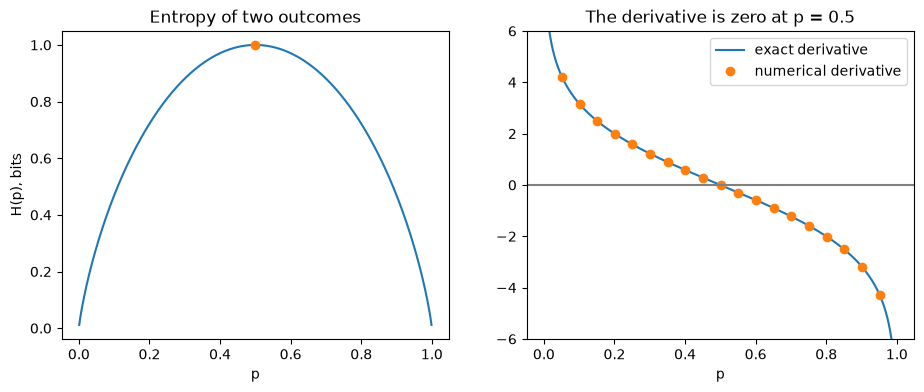

In [7]:
def binary_entropy(p):

    return -p * np.log2(p) - (1 - p) * np.log2(1 - p)


p = np.linspace(0.001, 0.999, 999)
h = 0.000001
numerical = (binary_entropy(p + h) - binary_entropy(p - h)) / (2 * h)
exact = np.log2((1 - p) / p)

print("binary_entropy(0.3) =", round(binary_entropy(0.3), 6), "| entropy([0.3, 0.7]) =", round(entropy([0.3, 0.7]), 6))
print("largest difference between the two derivatives:", np.max(np.abs(numerical - exact)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(p, binary_entropy(p))
axes[0].plot(0.5, 1, "o")
axes[0].set_xlabel("p")
axes[0].set_ylabel("H(p), bits")
axes[0].set_title("Entropy of two outcomes")
axes[1].plot(p, exact, label="exact derivative")
axes[1].plot(p[::50], numerical[::50], "o", label="numerical derivative")
axes[1].axhline(0, color="gray")
axes[1].set_ylim(-6, 6)
axes[1].set_xlabel("p")
axes[1].set_title("The derivative is zero at p = 0.5")
axes[1].legend()

plt.show()

## 3. The data: AdventureWorksDW

The model is built on AdventureWorksDW, Microsoft's sample data warehouse for BI (Microsoft, n.d.), shared under the MIT license. I downloaded this ZIP file from the official GitHub page of the SQL Server samples:

https://github.com/Microsoft/sql-server-samples/releases/download/adventureworks/AdventureWorksDW-data-warehouse-install-script.zip

and copied two of its files into the folder `data`:

| File | What it contains |
|---|---|
| `FactInternetSales.csv` | the internet sales, one row per order line |
| `DimSalesTerritory.csv` | the sales territories: region, country and territory group |

The files have no header row, and the values are separated by `|`. The order of the columns is in the script `instawdbdw.sql` from the same ZIP (the `CREATE TABLE` statements). In `FactInternetSales` the territory key is column 7 and SalesAmount is column 18. In `DimSalesTerritory` the key, the region, the country and the group are columns 0, 2, 3 and 4.

The next cell answers 'show sales by region' in three different ways. Three regions of the United States (Southeast, Northeast and Central) have almost no internet sales, so their bars are almost empty.


rows in FactInternetSales: 60398
regions: 10 | countries: 6 | territory groups: 3


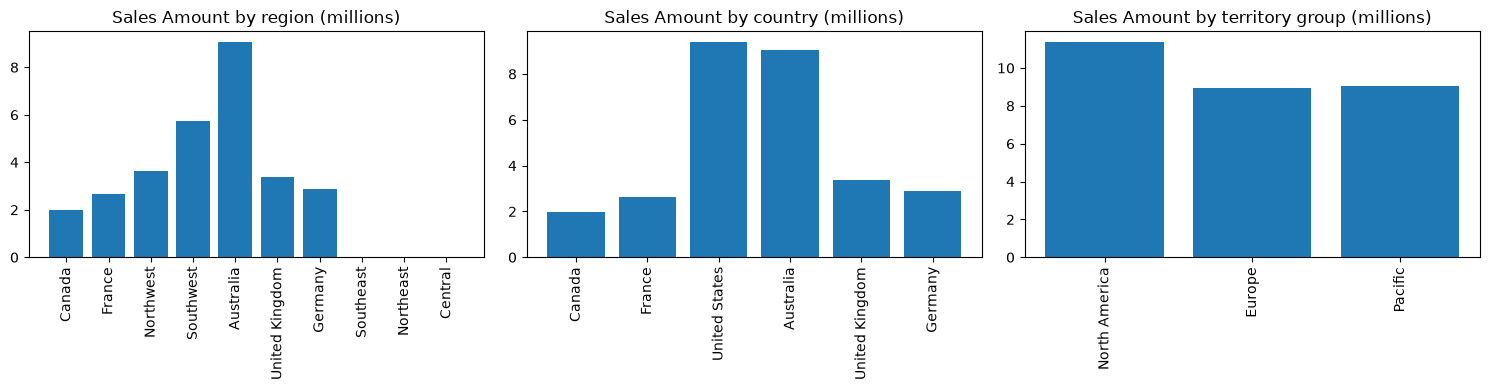

In [8]:
region_of = {}
country_of = {}
group_of = {}

with open("data/DimSalesTerritory.csv") as file:

    for line in file:
        row = line.split("|")
        region_of[row[0]] = row[2]
        country_of[row[0]] = row[3]
        group_of[row[0]] = row[4]

by_region = {}
by_country = {}
by_group = {}
rows = 0

with open("data/FactInternetSales.csv") as file:

    for line in file:
        row = line.split("|")
        key = row[7]
        amount = float(row[18])
        by_region[region_of[key]] = by_region.get(region_of[key], 0) + amount
        by_country[country_of[key]] = by_country.get(country_of[key], 0) + amount
        by_group[group_of[key]] = by_group.get(group_of[key], 0) + amount
        rows = rows + 1

print("rows in FactInternetSales:", rows)
print("regions:", len(by_region), "| countries:", len(by_country), "| territory groups:", len(by_group))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, totals, title in [(axes[0], by_region, "by region"), (axes[1], by_country, "by country"),
                          (axes[2], by_group, "by territory group")]:
    names = list(totals.keys())
    millions = [totals[name] / 1000000 for name in names]
    ax.bar(names, millions)
    ax.set_title("Sales Amount " + title + " (millions)")
    ax.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

## 4. The simulation: semantic model and simulated users

The semantic model on top of AdventureWorksDW has

* 6 measures: Sales Amount, Order Quantity, Order Count, Total Product Cost, Freight and Average Unit Price. Each measure is a column of `FactInternetSales` with an aggregation (SUM, AVERAGE or COUNT);
* 6 groupings, the columns that we group by, like the axis of a chart: Region, Country, Territory Group, Product Category, Product Subcategory and Month;
* 4 periods: Last Year (the latest year in the data), Previous Year (the year before it), Last Quarter (the latest three months) and All Time.

The simulated users - there are no real users, so the requests are simulated. Every request is made in two steps:

1. The true meaning is drawn: the measure, the grouping and the period that the user really wants, each with fixed probabilities.
2. The words are drawn. Every value has a few phrases with probabilities. Some phrases belong to several values (sales, orders, cost, market, location, product type, recently), and these make the requests ambiguous. The usual period (Last Year) is left out 70% of the time and the other periods 20% of the time. A SUM measure gets the word 'total' in front 20% of the time. At the end the words are put into one of eight sentence templates.

All these numbers are my assumptions, not measurements. They are all in the next cell, so they are easy to check and change.

`rng.choice(options, p=probabilities)` from NumPy draws one option with the given probabilities, like a 'discrete random variable'. A fixed 'seed' makes the random numbers repeatable: the same seed always gives the same 600 requests. 120 of them (20%) become example requests with a known meaning for the semantic layer. The other 480 are used for testing.


In [9]:
MEASURES = {"Sales Amount": ("SalesAmount", "SUM"), "Order Quantity": ("OrderQuantity", "SUM"),
            "Order Count": ("SalesOrderNumber", "COUNT"), "Total Product Cost": ("TotalProductCost", "SUM"),
            "Freight": ("Freight", "SUM"), "Average Unit Price": ("UnitPrice", "AVERAGE")}


MEASURE_WEIGHTS = {"Sales Amount": 0.30, "Order Quantity": 0.20, "Order Count": 0.15,
                   "Total Product Cost": 0.15, "Freight": 0.10, "Average Unit Price": 0.10}

GROUPING_WEIGHTS = {"Region": 0.20, "Country": 0.25, "Territory Group": 0.10,
                    "Product Category": 0.20, "Product Subcategory": 0.10, "Month": 0.15}

PERIOD_WEIGHTS = {"Last Year": 0.45, "Previous Year": 0.20, "Last Quarter": 0.20, "All Time": 0.15}

P_OMIT_PERIOD = {"Last Year": 0.70, "Previous Year": 0.20, "Last Quarter": 0.20, "All Time": 0.20}


MEASURE_PHRASES = {
    "Sales Amount": {"sales amount": 0.15, "revenue": 0.25, "turnover": 0.10, "sales": 0.35,
                     "takings": 0.05, "income": 0.10},
    "Order Quantity": {"order quantity": 0.10, "quantity": 0.20, "units sold": 0.20, "units": 0.10,
                       "sales": 0.15, "items sold": 0.10, "volume": 0.10, "orders": 0.05},
    "Order Count": {"order count": 0.10, "number of orders": 0.30, "orders": 0.40, "purchases": 0.20},
    "Total Product Cost": {"total product cost": 0.10, "product cost": 0.30, "cost of goods": 0.15,
                           "cogs": 0.10, "cost": 0.25, "costs": 0.10},
    "Freight": {"freight": 0.25, "shipping cost": 0.25, "shipping": 0.15, "delivery cost": 0.10,
                "cost": 0.15, "transport cost": 0.10},
    "Average Unit Price": {"average unit price": 0.15, "unit price": 0.25, "average price": 0.25,
                           "price": 0.25, "avg price": 0.10},
}

GROUPING_PHRASES = {
    "Region": {"region": 0.35, "regions": 0.20, "area": 0.10, "territory": 0.10, "market": 0.15,
               "location": 0.10},
    "Country": {"country": 0.40, "countries": 0.25, "nation": 0.05, "market": 0.15, "location": 0.15},
    "Territory Group": {"territory group": 0.15, "continent": 0.30, "group": 0.10, "world region": 0.15,
                        "market": 0.15, "geography": 0.15},
    "Product Category": {"product category": 0.20, "category": 0.35, "categories": 0.15,
                         "product type": 0.20, "product line": 0.10},
    "Product Subcategory": {"product subcategory": 0.15, "subcategory": 0.35, "subcategories": 0.15,
                            "product type": 0.20, "kind of product": 0.15},
    "Month": {"month": 0.45, "months": 0.15, "monthly": 0.20, "calendar month": 0.10, "each month": 0.10},
}

PERIOD_PHRASES = {
    "Last Year": {"last year": 0.45, "in the last year": 0.15, "this past year": 0.15, "latest year": 0.15,
                  "recently": 0.10},
    "Previous Year": {"previous year": 0.40, "the year before": 0.25, "prior year": 0.25,
                      "year before last": 0.10},
    "Last Quarter": {"last quarter": 0.50, "latest quarter": 0.20, "past quarter": 0.20, "recently": 0.10},
    "All Time": {"all time": 0.35, "all years": 0.25, "overall": 0.20, "since the start": 0.10, "ever": 0.10},
}

TEMPLATES = ["what was the {metric} by {grouping}{period}?", "can you show {metric} by {grouping}{period}?",
             "show {metric} by {grouping}{period}", "give me {metric} per {grouping}{period}",
             "list {metric} for each {grouping}{period}", "break down {metric} by {grouping}{period}",
             "{metric} by {grouping}{period}", "{metric} {grouping}{period}"]


for table in [MEASURE_PHRASES, GROUPING_PHRASES, PERIOD_PHRASES]:
    for value in table:
        assert abs(sum(table[value].values()) - 1) < 1e-9, value
print("The probabilities of the phrases sum to 1 for every value.")

The probabilities of the phrases sum to 1 for every value.


In [10]:
def pick(rng, weights):
    
    options = list(weights.keys())
    probabilities = list(weights.values())
    return str(rng.choice(options, p=probabilities))


def generate_requests(n, seed):
    
    rng = np.random.default_rng(seed)
    requests = []

    for _ in range(n):

        measure = pick(rng, MEASURE_WEIGHTS)
        grouping = pick(rng, GROUPING_WEIGHTS)
        period = pick(rng, PERIOD_WEIGHTS)
        column, aggregation = MEASURES[measure]
        
        metric_words = pick(rng, MEASURE_PHRASES[measure])
        if aggregation == "SUM" and "total" not in metric_words and rng.random() < 0.20:
            metric_words = "total " + metric_words
        grouping_words = pick(rng, GROUPING_PHRASES[grouping])
        if rng.random() < P_OMIT_PERIOD[period]:
            period_words = ""
        else:
            period_words = " " + pick(rng, PERIOD_PHRASES[period])
        template = TEMPLATES[rng.integers(len(TEMPLATES))]
        text = template.format(metric=metric_words, grouping=grouping_words, period=period_words)
        requests.append({"text": text, "measure": measure, "column": column, "aggregation": aggregation,
                         "grouping": grouping, "period": period, "has_period": period_words != ""})
    return requests


def split_requests(requests, seed):
    
    rng = np.random.default_rng(seed + 10000)
    order = rng.permutation(len(requests))
    n_examples = len(requests) // 5
    examples = [requests[i] for i in order[:n_examples]]
    test = [requests[i] for i in order[n_examples:]]
    return examples, test


SEED = 0
requests = generate_requests(600, SEED)
examples, test = split_requests(requests, SEED)

no_period = [r for r in requests if not r["has_period"]]
print(len(requests), "requests:", len(examples), "examples for the semantic layer and", len(test), "for testing")
print("the period is missing in", round(100 * len(no_period) / len(requests), 1), "% of the requests")
print()
for r in requests[:6]:
    print(r["text"], " ->", r["measure"], "/", r["grouping"], "/", r["period"])

600 requests: 120 examples for the semantic layer and 480 for testing
the period is missing in 43.8 % of the requests

order count market this past year  -> Order Count / Country / Last Year
break down order count by calendar month  -> Order Count / Month / Last Quarter
what was the cost of goods by regions?  -> Total Product Cost / Region / All Time
what was the product cost by product line prior year?  -> Total Product Cost / Product Category / Previous Year
break down cost by country  -> Total Product Cost / Country / Last Year
unit price countries previous year  -> Average Unit Price / Country / Previous Year


## 5. The assistant with and without a semantic layer

Both assistants use the Naive Bayes classifier from Section 2.3 (Jurafsky & Martin, 2026), with one classifier for every part of the request. They only differ in what they know:

| | Without semantic layer | With semantic layer |
|---|---|---|
| Parts of a request | column, aggregation, grouping, period | measure, grouping, period |
| Interpretations $N$ | $6 \cdot 3 \cdot 6 \cdot 4 = 432$ | $6 \cdot 6 \cdot 4 = 144$ |
| What it knows | the column names as words (*SalesTerritoryRegion* → "sales territory region") and a few common words for aggregations and periods | for every measure and grouping: its name, its column, a description and synonyms (like the properties of a measure in Power BI), plus the 120 example requests |
| Prior probabilities | all equal | all equal, except the period: 0.7 for Last Year (the default rule "no period means last year") |

Without a semantic layer the assistant does not know which aggregation goes with which column, so the measure splits into two parts: a column and an aggregation.

For every test request the function `build_assistant` keeps three things for every part: the probabilities of its values, the best guess (the most probable value) and the true value. If several values are exactly equally probable, the best guess is chosen among them at random: an assistant with no clue should not be lucky just because the most common value happens to be first in the list. Every request gets its own random numbers (a seed made from the seed of the experiment and the number of the request), so the result does not depend on the order of the calculations.


In [11]:
PERIOD_WORDS = {"Last Year": ["last year"], "Previous Year": ["previous year", "prior year", "the year before"],
                "Last Quarter": ["last quarter", "past quarter"], "All Time": ["all time", "all years", "overall"]}

WITHOUT_LAYER = {
    "column": {"SalesAmount": ["sales amount"], "OrderQuantity": ["order quantity"],
               "SalesOrderNumber": ["sales order number"], "TotalProductCost": ["total product cost"],
               "Freight": ["freight"], "UnitPrice": ["unit price"]},
    "aggregation": {"SUM": ["total", "sum"], "AVERAGE": ["average", "avg", "mean"],
                    "COUNT": ["number", "count", "how many"]},
    "grouping": {"Region": ["sales territory region"], "Country": ["sales territory country"],
                 "Territory Group": ["sales territory group"], "Product Category": ["english product category name"],
                 "Product Subcategory": ["english product subcategory name"], "Month": ["english month name"]},
    "period": PERIOD_WORDS,
}


WITH_LAYER = {
    "measure": {
        "Sales Amount": ["Sales Amount", "sales amount", "total revenue of internet sales in currency",
                         "revenue", "turnover", "sales"],
        "Order Quantity": ["Order Quantity", "order quantity", "total number of product units ordered",
                           "quantity", "units", "units sold"],
        "Order Count": ["Order Count", "sales order number", "number of distinct sales orders placed by customers",
                        "orders", "number of orders"],
        "Total Product Cost": ["Total Product Cost", "total product cost",
                               "standard cost of the products that were sold",
                               "product cost", "cost of goods", "cogs"],
        "Freight": ["Freight", "freight", "shipping charges for delivering the orders",
                    "shipping cost", "shipping", "delivery cost"],
        "Average Unit Price": ["Average Unit Price", "unit price", "average selling price of one product unit",
                               "unit price", "average price", "price"],
    },
    "grouping": {
        "Region": ["Region", "sales territory region", "sales territory region of the customer",
                   "region", "regions", "area"],
        "Country": ["Country", "sales territory country", "country of the sales territory",
                    "country", "countries"],
        "Territory Group": ["Territory Group", "sales territory group",
                            "group of territories such as Europe or North America", "continent", "group"],
        "Product Category": ["Product Category", "english product category name",
                             "top level category of the product such as Bikes", "category", "categories"],
        "Product Subcategory": ["Product Subcategory", "english product subcategory name",
                                "detailed subcategory of the product such as Mountain Bikes",
                                "subcategory", "subcategories"],
        "Month": ["Month", "english month name", "calendar month of the order date", "month", "monthly"],
    },
    "period": PERIOD_WORDS,
}

for name, knowledge in [("without layer", WITHOUT_LAYER), ("with layer", WITH_LAYER)]:
    for part in knowledge:
        n_texts = 0
        for value in knowledge[part]:
            n_texts = n_texts + len(knowledge[part][value])
        print(name, "|", part, "|", len(knowledge[part]), "values |", n_texts, "known texts")

without layer | column | 6 values | 6 known texts
without layer | aggregation | 3 values | 8 known texts
without layer | grouping | 6 values | 6 known texts
without layer | period | 4 values | 9 known texts
with layer | measure | 6 values | 35 known texts
with layer | grouping | 6 values | 31 known texts
with layer | period | 4 values | 9 known texts


In [12]:
def build_assistant(knowledge, examples, test, period_prior, seed):
    # 1. learning: one Naive Bayes model for every part of the request
    models = {}
    for part in knowledge:
        training = []
        for value in knowledge[part]:
            for text in knowledge[part][value]:
                training.append((text, value))
        for r in examples:
            training.append((r["text"], r[part]))
        prior = None
        if part == "period":
            prior = period_prior
        models[part] = train_naive_bayes(training, list(knowledge[part]), prior)

    # 2. every test request: probabilities, best guess and true value of every part
    results = []
    for i in range(len(test)):
        rng = np.random.default_rng([seed, i])
        r = {"probs": {}, "guess": {}, "truth": {}}
        for part in models:
            p = predict(models[part], test[i]["text"])
            r["probs"][part] = p
            
            r["guess"][part] = int(np.argmax(p + rng.random(len(p)) * 1e-12))
            r["truth"][part] = list(knowledge[part]).index(test[i][part])
        results.append(r)
    return results


no_layer = build_assistant(WITHOUT_LAYER, [], test, None, SEED)
with_layer = build_assistant(WITH_LAYER, examples, test, [0.7, 0.1, 0.1, 0.1], SEED)

print("Request:", test[0]["text"])
print()
for name, assistant in [("without layer", no_layer), ("with layer", with_layer)]:
    for part in assistant[0]["probs"]:
        p = assistant[0]["probs"][part]
        print(name, "|", part, "|", p.round(2), "| H =", round(entropy(p), 2), "bits")
    print()

Request: shipping by continent in the last year

without layer | column | [0.17 0.17 0.17 0.17 0.17 0.17] | H = 2.58 bits
without layer | aggregation | [0.33 0.33 0.33] | H = 1.58 bits
without layer | grouping | [0.17 0.17 0.17 0.17 0.17 0.17] | H = 2.58 bits
without layer | period | [0.47 0.28 0.18 0.08] | H = 1.75 bits

with layer | measure | [0.11 0.3  0.07 0.03 0.43 0.06] | H = 2.05 bits
with layer | grouping | [0.1  0.12 0.33 0.15 0.1  0.2 ] | H = 2.44 bits
with layer | period | [0.47 0.45 0.07 0.01] | H = 1.34 bits



## 6. The dialogue: when to ask and what to ask

In one conversation the assistant repeats three steps:

1. Look at the parts that are still open (not asked yet).
2. Decide: answer now, or ask about one open part?
3. If it asks, the user answers correctly, so that part becomes certain and is no longer open.

It stops when the rule says "answer", or after 3 questions. Then it answers with its best guess for every open part. The answer is correct only if all these guesses are right.

We test two rules for step 2:

| Rule | Ask while | Ask about |
|---|---|---|
| Entropy rule (the proposed one) | $\sum_{i \text{ open}} H(C_i) > \tau$ | the open part with the largest entropy |
| Probability rule (by analogy with earlier systems; Jurafsky & Martin, 2026) | $\prod_{i \text{ open}} m_i < \theta$ | the open part with the smallest $m_i$ |

Here $m_i$ is the probability of the best guess for part $i$, so the product is the chance that the whole answer is right. A correct answer removes the whole entropy of the asked part, so the entropy rule asks the question that gives the most information. The threshold $\tau$ (in bits) expresses how expensive a question is compared with a mistake (Horvitz, 1999): a small $\tau$, or a big $\theta$, means more questions and fewer mistakes.

In [13]:
def run_dialogue(r, rule, threshold, max_questions=3):
    open_parts = list(r["probs"])
    questions = 0
    while questions < max_questions and len(open_parts) > 0:
        if rule == "entropy":
            H = 0
            for part in open_parts:
                H = H + entropy(r["probs"][part])
            if H <= threshold:
                break
            ask = open_parts[0]
            for part in open_parts:
                if entropy(r["probs"][part]) > entropy(r["probs"][ask]):
                    ask = part
        else:
            chance = 1
            for part in open_parts:
                chance = chance * max(r["probs"][part])
            if chance >= threshold:
                break
            ask = open_parts[0]
            for part in open_parts:
                if max(r["probs"][part]) < max(r["probs"][ask]):
                    ask = part
        open_parts.remove(ask)
        questions = questions + 1

    correct = True
    for part in open_parts:
        if r["guess"][part] != r["truth"][part]:
            correct = False
    return questions, correct


def evaluate(assistant, rule, threshold, max_questions=3):
    
    questions = []
    correct = []
    for r in assistant:
        q, c = run_dialogue(r, rule, threshold, max_questions)
        questions.append(q)
        correct.append(c)
    return np.array(questions), np.array(correct)


print("with semantic layer, entropy rule, τ = 1 bit:")
for i in range(5):
    q, c = run_dialogue(with_layer[i], "entropy", 1.0)
    print(" ", test[i]["text"], "-> questions:", q, "| correct answer:", c)

with semantic layer, entropy rule, τ = 1 bit:
  shipping by continent in the last year -> questions: 3 | correct answer: True
  list unit price for each territory prior year -> questions: 1 | correct answer: True
  what was the avg price by territory in the last year? -> questions: 2 | correct answer: True
  what was the avg price by category? -> questions: 3 | correct answer: True
  what was the quantity by category ever? -> questions: 3 | correct answer: True


## 7. Results

### 7.1 The four variants and the four hypotheses

The four variants are compared on the 480 test requests: without and with a semantic layer, without and with questions (entropy rule, $\tau = 1$ bit). For the accuracy we give a 95% confidence interval. By the central limit theorem the share of correct answers $\hat p$ is close to a normal distribution, so the interval is

$$\hat p \pm 1.96 \sqrt{\frac{\hat p (1 - \hat p)}{n}}, \qquad n = 480.$$

Every hypothesis gets a simple check and a standard test from SciPy (Virtanen et al., 2020), at significance level 0.05:

* H1 – in how many requests is the entropy lower with the semantic layer? Test: Wilcoxon signed-rank test for paired samples (the same 480 requests).
* H2 – take every pair of one wrong and one correct answer. How often does the wrong one have the higher entropy? This share is the AU*; 0.5 would mean no relation. Test: Mann–Whitney U test.
* H3 – count the answers that change from wrong to right and from right to wrong when questions are allowed. If questions did not help, every change would be like a fair coin, so the exact McNemar test is a binomial test with $p = 0.5$.
* H4 – the number of questions without and with the layer. Test: Wilcoxon signed-rank test.

There are 6 tests (H2 and H3 are tested for both assistants), so with the Bonferroni correction every p-value must be below $0.05 / 6 \approx 0.0083$.


In [14]:
def total_entropy(r):
    
    H = 0
    for part in r["probs"]:
        H = H + entropy(r["probs"][part])
    return H


results = {}
for name, assistant, N in [("without layer", no_layer, 432), ("with layer", with_layer, 144)]:
    H = np.array([total_entropy(r) for r in assistant])
    q0, c0 = evaluate(assistant, "entropy", 0, max_questions=0)
    q1, c1 = evaluate(assistant, "entropy", 1.0)
    results[name] = {"H": H, "c0": c0, "q1": q1, "c1": c1}
    for label, q, c in [("no questions", q0, c0), ("with questions", q1, c1)]:
        acc = c.mean()
        half = 1.96 * math.sqrt(acc * (1 - acc) / len(c))
        print(f"{name}, {label}: N = {N}, H = {H.mean():.2f} bits, questions = {q.mean():.2f}, "
              f"accuracy = {acc:.1%} (95% CI {acc - half:.1%} - {acc + half:.1%})")
print()

no = results["without layer"]
sl = results["with layer"]
p_values = []

# H1: is the entropy lower with the semantic layer?
p = stats.wilcoxon(no["H"], sl["H"], alternative="greater").pvalue
p_values.append(p)
print(f"H1: the entropy is lower with the layer in {np.mean(no['H'] > sl['H']):.1%} of the requests, "
      f"Wilcoxon p = {p:.1e}")

# H2: do wrong answers have a higher entropy than correct ones?
for name in results:
    H = results[name]["H"]
    correct = results[name]["c0"]
    wrong_H = H[~correct]
    right_H = H[correct]
    wins = 0
    for a in wrong_H:
        for b in right_H:
            if a > b:
                wins = wins + 1
            elif a == b:
                wins = wins + 0.5
    auc = wins / (len(wrong_H) * len(right_H))
    p = stats.mannwhitneyu(wrong_H, right_H, alternative="greater").pvalue
    p_values.append(p)
    print(f"H2, {name}: mean entropy {wrong_H.mean():.2f} bits if wrong and {right_H.mean():.2f} if correct, "
          f"AUC = {auc:.2f}, Mann-Whitney p = {p:.1e}")

# H3: do the questions turn wrong answers into right ones?
for name in results:
    before = results[name]["c0"]
    after = results[name]["c1"]
    fixed = np.sum(~before & after)
    broken = np.sum(before & ~after)
    p = stats.binomtest(int(fixed), int(fixed + broken), 0.5).pvalue
    p_values.append(p)
    print(f"H3, {name}: wrong -> right {fixed}, right -> wrong {broken}, McNemar p = {p:.1e}")

# H4: are fewer questions needed with the semantic layer?
p = stats.wilcoxon(no["q1"], sl["q1"], alternative="greater").pvalue
p_values.append(p)
print(f"H4: {no['q1'].mean():.2f} questions without and {sl['q1'].mean():.2f} with the layer, "
      f"Wilcoxon p = {p:.1e}")
print()
print("all 6 p-values are below 0.05 / 6:", all(p < 0.05 / 6 for p in p_values))

without layer, no questions: N = 432, H = 8.37 bits, questions = 0.00, accuracy = 9.8% (95% CI 7.1% - 12.5%)
without layer, with questions: N = 432, H = 8.37 bits, questions = 3.00, accuracy = 68.8% (95% CI 64.6% - 72.9%)
with layer, no questions: N = 144, H = 3.87 bits, questions = 0.00, accuracy = 50.0% (95% CI 45.5% - 54.5%)
with layer, with questions: N = 144, H = 3.87 bits, questions = 2.16, accuracy = 91.0% (95% CI 88.5% - 93.6%)

H1: the entropy is lower with the layer in 100.0% of the requests, Wilcoxon p = 1.2e-80
H2, without layer: mean entropy 8.40 bits if wrong and 8.14 if correct, AUC = 0.75, Mann-Whitney p = 8.6e-09
H2, with layer: mean entropy 4.10 bits if wrong and 3.64 if correct, AUC = 0.62, Mann-Whitney p = 5.3e-06
H3, without layer: wrong -> right 283, right -> wrong 0, McNemar p = 1.3e-85
H3, with layer: wrong -> right 197, right -> wrong 0, McNemar p = 1.0e-59
H4: 3.00 questions without and 2.16 with the layer, Wilcoxon p = 1.5e-71

all 6 p-values are below 0.05 /

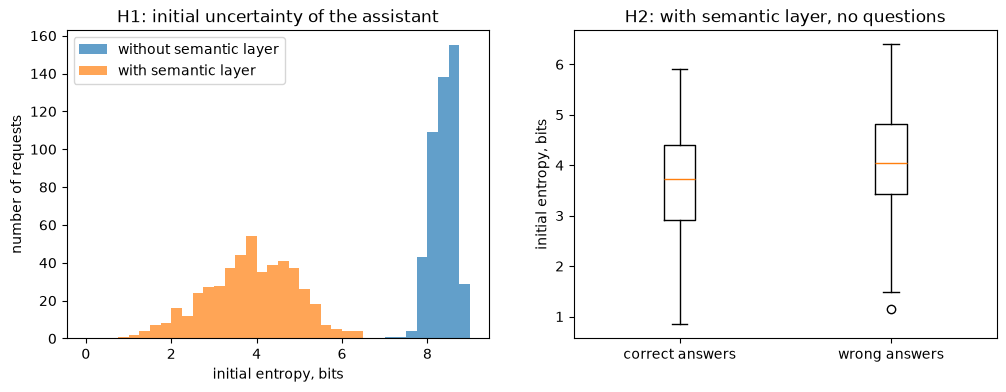

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bins = np.linspace(0, 9, 37)
axes[0].hist(no["H"], bins=bins, alpha=0.7, label="without semantic layer")
axes[0].hist(sl["H"], bins=bins, alpha=0.7, label="with semantic layer")
axes[0].set_xlabel("initial entropy, bits")
axes[0].set_ylabel("number of requests")
axes[0].set_title("H1: initial uncertainty of the assistant")
axes[0].legend()

correct = sl["c0"]
axes[1].boxplot([sl["H"][correct], sl["H"][~correct]])
axes[1].set_xticks([1, 2], ["correct answers", "wrong answers"])
axes[1].set_ylabel("initial entropy, bits")
axes[1].set_title("H2: with semantic layer, no questions")
plt.show()

### 7.2 Choosing the threshold, and comparing the two rules

Every threshold gives a different balance between accuracy and questions. We try $\tau$ from 0 to 9 bits (step 0.25) and $\theta$ from 0 to 1 (step 0.025), and draw the accuracy against the mean number of questions.

To compare the two rules with one number, we use the mean accuracy for a budget of 0 to 2 questions per request: the area under the curve between 0 and 2 questions, divided by 2. The area is found with the trapezoidal rulе, as for integrals in calculus. `np.interp` joins the measured points with straight lines and reads the curve at 201 points between 0 and 2.


without layer: mean accuracy for 0-2 questions: entropy rule 0.216, probability rule 0.291
with layer: mean accuracy for 0-2 questions: entropy rule 0.680, probability rule 0.720
   τ = 0.5: accuracy 98.5% with 2.68 questions
   τ = 1.0: accuracy 91.0% with 2.16 questions
   τ = 1.5: accuracy 80.8% with 1.77 questions
   τ = 2.0: accuracy 75.6% with 1.47 questions


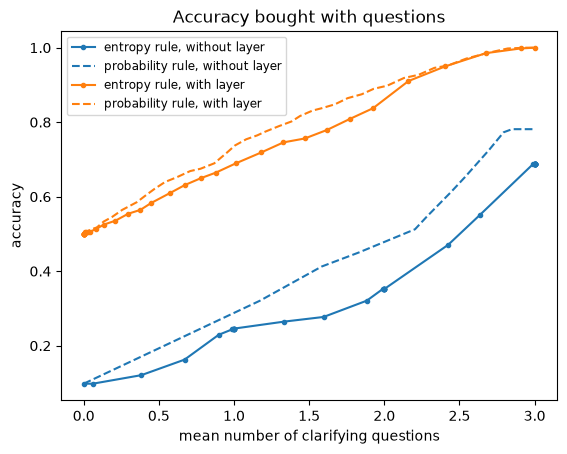

In [16]:
TAUS = np.arange(0, 9.01, 0.25)
THETAS = np.arange(0, 1.0001, 0.025)

def sweep(assistant, rule, thresholds):
    
    mean_questions = []
    accuracy = []
    for t in thresholds:
        q, c = evaluate(assistant, rule, t)
        mean_questions.append(q.mean())
        accuracy.append(c.mean())
    return np.array(mean_questions), np.array(accuracy)


def mean_accuracy_0_to_2(mean_questions, accuracy):
    
    order = np.argsort(mean_questions)
    budgets = np.linspace(0, 2, 201)
    curve = np.interp(budgets, mean_questions[order], accuracy[order])
    return np.trapezoid(curve, budgets) / 2


for name, assistant, color in [("without layer", no_layer, "tab:blue"), ("with layer", with_layer, "tab:orange")]:
    q_e, acc_e = sweep(assistant, "entropy", TAUS)
    q_p, acc_p = sweep(assistant, "probability", THETAS)
    plt.plot(q_e, acc_e, "-o", markersize=3, color=color, label="entropy rule, " + name)
    plt.plot(q_p, acc_p, "--", color=color, label="probability rule, " + name)
    print(f"{name}: mean accuracy for 0-2 questions: entropy rule {mean_accuracy_0_to_2(q_e, acc_e):.3f}, "
          f"probability rule {mean_accuracy_0_to_2(q_p, acc_p):.3f}")
    if name == "with layer":
        for t, q, acc in zip(TAUS, q_e, acc_e):
            if t in [0.5, 1.0, 1.5, 2.0]:
                print(f"   τ = {t}: accuracy {acc:.1%} with {q:.2f} questions")

plt.xlabel("mean number of clarifying questions")
plt.ylabel("accuracy")
plt.title("Accuracy bought with questions")
plt.legend(fontsize="small")
plt.show()

Why does the probability rule win? The chance that the whole answer is right is $m_1 \cdot m_2 \cdots m_k$. A right answer about part $j$ makes $m_j = 1$, so it multiplies the chance by $1/m_j$, and this is the largest for the part with the smallest $m_j$. Entropy also measures how the rest of the probability is spread over the wrong values, and that does not change whether the best guess is right. For example, part A = (0.5, 0.5) has 1 bit and part B = (0.7, 0.1, 0.1, 0.1) has 1.36 bits. The entropy rule asks about B, but a question about A doubles the chance of a right answer ($1/0.5 = 2$), while a question about B multiplies it only by $1/0.7 \approx 1.43$. Information and accuracy are different goals.

### 7.3 Robustness

All results so far come from one set of random requests (seed 0). Two more checks:

1. A stronger default rule: the prior for Last Year is 0.9 instead of 0.7.
2. 20 repetitions: the whole experiment is repeated with seeds 0 to 19, so with new requests, new examples and new test requests. In every repetition we check the direction of H1–H4 and which rule is better. To save time, the thresholds go in bigger steps (0.5 bits and 0.05).


In [17]:
strong = build_assistant(WITH_LAYER, examples, test, [0.9, 0.1 / 3, 0.1 / 3, 0.1 / 3], SEED)
q, c = evaluate(strong, "entropy", 1.0)
print(f"prior 0.9 for Last Year, τ = 1: accuracy {c.mean():.1%} with {q.mean():.2f} questions")
print()


accuracies = []
all_hold = 0
wins = {"without layer": 0, "with layer": 0}
for seed in range(20):
    requests_s = generate_requests(600, seed)
    examples_s, test_s = split_requests(requests_s, seed)
    no_s = build_assistant(WITHOUT_LAYER, [], test_s, None, seed)
    sl_s = build_assistant(WITH_LAYER, examples_s, test_s, [0.7, 0.1, 0.1, 0.1], seed)

    H_no = np.array([total_entropy(r) for r in no_s])
    H_sl = np.array([total_entropy(r) for r in sl_s])
    q0_no, c0_no = evaluate(no_s, "entropy", 0, max_questions=0)
    q0_sl, c0_sl = evaluate(sl_s, "entropy", 0, max_questions=0)
    q1_no, c1_no = evaluate(no_s, "entropy", 1.0)
    q1_sl, c1_sl = evaluate(sl_s, "entropy", 1.0)
    h1 = H_no.mean() > H_sl.mean()
    h2 = H_no[~c0_no].mean() > H_no[c0_no].mean() and H_sl[~c0_sl].mean() > H_sl[c0_sl].mean()
    h3 = c1_no.mean() > c0_no.mean() and c1_sl.mean() > c0_sl.mean()
    h4 = q1_no.mean() > q1_sl.mean()
    if h1 and h2 and h3 and h4:
        all_hold = all_hold + 1
    accuracies.append(c1_sl.mean())

    for name, assistant in [("without layer", no_s), ("with layer", sl_s)]:
        q_e, acc_e = sweep(assistant, "entropy", np.arange(0, 9.01, 0.5))
        q_p, acc_p = sweep(assistant, "probability", np.arange(0, 1.0001, 0.05))
        if mean_accuracy_0_to_2(q_p, acc_p) > mean_accuracy_0_to_2(q_e, acc_e):
            wins[name] = wins[name] + 1

accuracies = np.array(accuracies)
print("H1-H4 all point the right way in", all_hold, "of 20 repetitions")
print(f"accuracy with the layer at τ = 1: mean {accuracies.mean():.1%}, "
      f"standard deviation {100 * accuracies.std(ddof=1):.1f} points")
print("the probability rule is better in", wins["without layer"], "(without layer) and",
      wins["with layer"], "(with layer) of the 20 repetitions")


prior 0.9 for Last Year, τ = 1: accuracy 71.9% with 1.96 questions

H1-H4 all point the right way in 20 of 20 repetitions
accuracy with the layer at τ = 1: mean 91.0%, standard deviation 2.0 points
the probability rule is better in 20 (without layer) and 20 (with layer) of the 20 repetitions


## 8. Conclusion

The model treats a conversation with data as removing uncertainty step by step. It counts the interpretations of a request, estimates their probabilities with Naive Bayes, measures the uncertainty with Shannon entropy and decides with a threshold when to ask.

* H1 is supported. The semantic layer lowers the initial uncertainty from 8.37 to 3.87 bits, and it is lower for every one of the 480 test requests. Part of this is pure counting (144 instead of 432 interpretations). The rest comes from the synonyms, the descriptions, the example requests and the default period.
* H2 is supported, but the relation is not perfect. A wrong answer has a higher entropy than a correct one in about 75% of the pairs without the layer and in about 62% of the pairs with it.
* H3 is supported. With $\tau = 1$ bit the questions raise the accuracy from 9.8% to 68.8% without the layer and from 50.0% to 91.0% with it, and no correct answer becomes wrong.
* H4 is supported. Without the layer the assistant always uses all 3 questions and is still less accurate than the assistant with the layer, which needs 2.16 questions on average.

The threshold works like a control knob: $\tau = 2$ gives 75.6% accuracy with 1.47 questions, and $\tau = 0.5$ gives 98.5% with 2.68 questions. The surprise is that for deciding when to ask, the probability of the most likely interpretation works better than entropy: 0.720 against 0.680 with the layer, 0.291 against 0.216 without it, and better in all 20 repetitions. Information and accuracy are different goals. A default rule helps only as long as it is right: with a prior of 0.9 the accuracy at $\tau = 1$ falls to 71.9%.

Limitations. The requests and the users are simulated, and the word frequencies are my assumptions. The assistant without a semantic layer is weak on purpose, because a modern language model knows many business words. The parts of a request are treated as independent, while real requests also have filters, comparisons and rankings.

Next steps. A rule that compares the value of a question with its cost, a user who sometimes answers wrongly, probabilities from a large language model instead of Naive Bayes, and tests with real users.


## 9. References

* Horvitz, E. (1999). Principles of mixed-initiative user interfaces. In *Proceedings of the SIGCHI Conference on Human Factors in Computing Systems* (pp. 159–166). ACM. https://doi.org/10.1145/302979.303030
* Jurafsky, D., & Martin, J. H. (2026). *Speech and language processing* (3rd ed. draft). https://web.stanford.edu/~jurafsky/slp3/
* Microsoft. (n.d.). *AdventureWorks sample databases*. Microsoft Learn. https://learn.microsoft.com/en-us/sql/samples/adventureworks-install-configure
* Sequeda, J., Allemang, D., & Jacob, B. (2023). *A benchmark to understand the role of knowledge graphs on large language model's accuracy for question answering on enterprise SQL databases* (arXiv:2311.07509). https://arxiv.org/abs/2311.07509
* Shannon, C. E. (1948). A mathematical theory of communication. *Bell System Technical Journal, 27*(3), 379–423. https://doi.org/10.1002/j.1538-7305.1948.tb01338.x
* Virtanen, P., Gommers, R., Oliphant, T. E., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*, 261–272. https://doi.org/10.1038/s41592-019-0686-2
* Zhao, F., Deep, S., Psallidas, F., Floratou, A., Agrawal, D., & El Abbadi, A. (2024). Sphinteract: Resolving ambiguities in NL2SQL through user interaction. *Proceedings of the VLDB Endowment, 18*(4), 1145–1158. https://doi.org/10.14778/3717755.3717772
